# 08 – Extra data: promotions, stores, oil

Besides sales, the competition gives us more files: promotions, store information, oil prices, transactions.
More data isn't automatically better: every extra column must be **known at forecast time**, and it must
**improve the backtest consistently**, not just by noise.

**Plan:**
1. Which extra data may we use, and from when?
2. Promotions: how strong is the effect?
3. A quick look at oil prices and store information.
4. Backtest each group, one at a time.
5. Decide, and make submission v4.

The code is in `src/extra.py` (with tests in `tests/test_extra.py`); `build_table(..., extras=...)` adds the groups.

*Running time: about 25 minutes, mostly the three backtests.*

> **Note, added later:** submission v4 scored **0.41332** on Kaggle, worse than v3 (0.40358), although the backtest expected an improvement. The cause was found in **notebook 09**: on 16 August, every store had a promotion in a few families, which never happened in training. The decisions in this notebook still hold: without those rows, promotions improve the Kaggle score too.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_test, load_train
from src.dataset import build_table
from src.extra import load_oil
from src.features import load_holidays, load_stores
from src.lags import closed_store_days
from src.model import backtest_model, fit, forecast, prepare
from src.validation import make_cutoffs

IMAGES = "../images"

train = load_train()
test = load_test()
stores, holidays, oil = load_stores(), load_holidays(), load_oil()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)

## 1. When would we know it?

The same question as for lag features (notebook 05), asked for each file:

| Data | Known for the forecast days? | How we use it |
|---|---|---|
| **Promotions** (`onpromotion`) | **Yes**: promotions are planned in advance, and `test.csv` contains them | The forecast day's own value |
| **Store info** (type, cluster) | Yes: fixed facts about each store | As categories |
| **Oil price** | **No**: `oil.csv` has prices for the test days, but in reality nobody knows the future oil price | Only prices at least 16 days old |
| **Transactions** (receipts per store) | No: none for the test period | Not used: only usable 16 days old, and mostly repeats total sales |

The oil row is a trap: the file contains the future prices, so the code would run without complaint.
But a model that uses them can't be used for real forecasting. Data being *available in the file*
doesn't mean it would be *known at forecast time*.

The tests in `tests/test_extra.py` check both sides of the promotion rule: changing the forecast day's own
promotion **must** change the features, and changing the 15 days before it **must not**. A planted leak
(`promo_vs_recent` computed from yesterday's promotions) made the second test fail.

## 2. Promotions

`onpromotion` is the number of items in a family on promotion in a store on a day. How often are there promotions?

In [2]:
share_by_year = train.groupby(train["date"].dt.year)["onpromotion"].apply(lambda s: (s > 0).mean())
print("Share of rows with a promotion, by year:")
print(share_by_year.round(3).to_string())
print(f"Test period: {(test['onpromotion'] > 0).mean():.3f}")

Share of rows with a promotion, by year:
date
2013    0.000
2014    0.100
2015    0.209
2016    0.351
2017    0.453
Test period: 0.441


Promotions barely existed before April 2014 and became much more common since; the test period looks like 2017.

**How much more does a series sell on promotion days?** Within each series (so that a big series doesn't look
"promoted" just because it's big), compare the average `log1p(sales)` on days with and without a promotion, 2016–2017.

One lesson from notebook 07 applies here too: **leave out the days a store was closed.** A closed store has no
promotions and no sales, so those days would land in the "no promotion" group and make promotions look far stronger
than they are. We compute the comparison both ways to see how much it matters:

1,573 series have days with and without promotions
Median extra sales on promotion days: 36% with closed days, 19% with open days only
GROCERY I days without a promotion: 1,146, of which the store was closed: 760


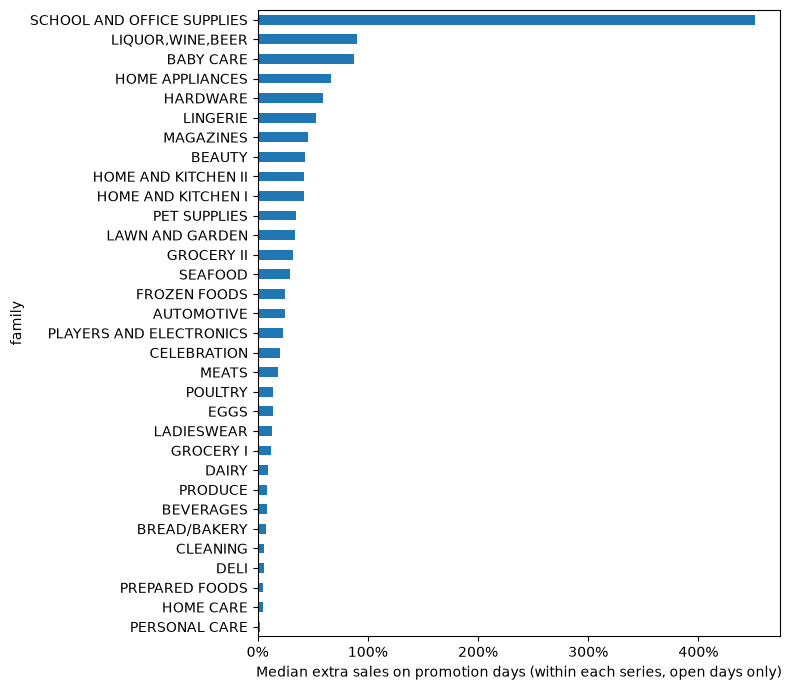

In [3]:
closed = closed_store_days(wide).stack(["store_nbr", "family"], future_stack=True).rename("closed").reset_index()
recent = (train[train["date"] >= "2016-01-01"]
          .merge(closed, on=["date", "store_nbr", "family"])
          .assign(log_sales=lambda d: np.log1p(d["sales"]), promoted=lambda d: d["onpromotion"] > 0))

def promotion_lift(rows):
    # Per series: mean log sales on promotion days minus on other days (a log difference).
    by_series = rows.groupby(["store_nbr", "family", "promoted"], observed=True)["log_sales"].mean().unstack()
    return (by_series[True] - by_series[False]).dropna()

lift_all = promotion_lift(recent)
lift = promotion_lift(recent[~recent["closed"]])
print(f"{len(lift):,} series have days with and without promotions")
print(f"Median extra sales on promotion days: {np.exp(lift_all.median()) - 1:.0%} with closed days, "
      f"{np.exp(lift.median()) - 1:.0%} with open days only")

grocery = recent[recent["family"] == "GROCERY I"]
no_promo = grocery[~grocery["promoted"]]
print(f"GROCERY I days without a promotion: {len(no_promo):,}, of which the store was closed: {int(no_promo['closed'].sum()):,}")

by_family = np.exp(lift.groupby(level="family", observed=True).median()) - 1
fig, ax = plt.subplots(figsize=(8, 7))
by_family.sort_values().plot.barh(ax=ax)
ax.set_xlabel("Median extra sales on promotion days (within each series, open days only)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout()
fig.savefig(f"{IMAGES}/promotion_lift.png", dpi=120)
plt.show()

**What we found:**
- **Closed days distort the comparison a lot.** With them, promotions seem to add 36% (and +1,400% for GROCERY I);
  with open days only, about **19%**. GROCERY I is on promotion almost every day, so most of its "no promotion" days
  were closed days. The first version of this chart showed the inflated numbers; an implausible bar was the clue.
- On open days, the typical series sells about a fifth more on promotion days; a few families much more.

*A caution about cause and effect:* this isn't proof that promotions **cause** the extra sales. Shops may put products
on promotion when demand is high anyway. School supplies (+450%) are the clearest case: their promotions run during
the back-to-school season, when sales would jump anyway (notebook 03). For forecasting that doesn't matter:
we only need promotions to **predict** sales, and they're known in advance. For a business question like
"should we run more promotions?", this comparison wouldn't be enough.

Two features in `promotion_features`:
- `promo`: log1p of the forecast day's own `onpromotion`;
- `promo_vs_recent`: `promo` minus its average over days 16–29 before. The lag features describe sales **under the recent
  promotion level**; this column says whether the forecast day has more or fewer promotions than that.

## 3. Oil and store information: a quick look

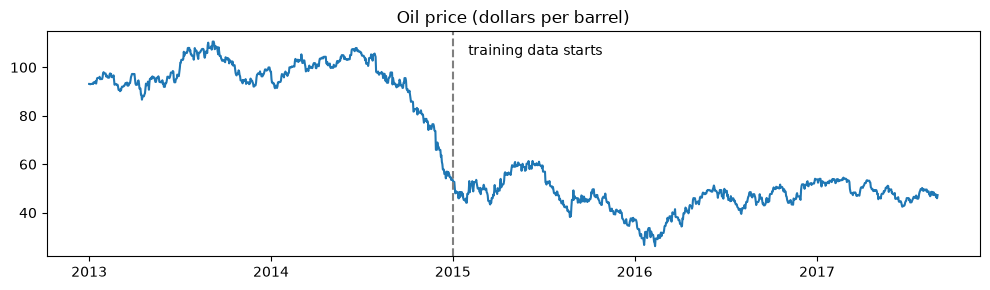

type,A,B,C,D,E
stores per type,9,8,15,18,4


In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(oil.index, oil.values)
ax.axvline(pd.Timestamp("2015-01-01"), color="grey", linestyle="--")
ax.text(pd.Timestamp("2015-02-01"), oil.max() * 0.95, "training data starts")
ax.set_title("Oil price (dollars per barrel)")
fig.tight_layout()
fig.savefig(f"{IMAGES}/oil_price.png", dpi=120)
plt.show()
stores["type"].value_counts().sort_index().rename("stores per type").to_frame().T

Ecuador's economy depends on oil, and the price collapsed in late 2014. But our training data starts in 2015, after the
collapse, when the price moved only between about 26 and 61 dollars (against about 100 before the collapse). So the model sees little oil variation to learn from:
don't expect much.

Store type (A–E) and cluster (17 groups of similar stores) describe the stores. The model already knows each store
through `store_nbr`, so these could only help where it knows a store poorly, like a newly opened one.

## 4. Backtest, one group at a time

Adding all groups at once would hide which one helps. So we add them one by one, and compare **window by window**
with the previous step (the rule of thumb from notebook 03: trust a change when it wins consistently).
The model without extras is the fixed model from notebook 07. Each backtest takes about 7 minutes.

In [5]:
cutoffs = make_cutoffs(wide.index.max(), n_windows=8)
experiments = {"promo": ("promo",), "promo + store": ("promo", "store"), "promo + store + oil": ("promo", "store", "oil")}

scores = {"no extras": [0.6162, 0.4507, 0.4274, 0.4000, 0.3931, 0.3835, 0.4059, 0.4672]}  # notebook 07, after the fix
for name, extras in experiments.items():
    data = prepare(build_table(train, stores, holidays, end="2017-08-31", extras=extras, test=test, oil=oil))
    result, _ = backtest_model(data, wide, cutoffs)
    scores[name] = result["RMSLE"].to_numpy()
scores = pd.DataFrame(scores, index=result.index)
summary = scores.copy()
summary.loc["mean"] = scores.mean()
summary.round(4)

,no extras,promo,promo + store,promo + store + oil
window starts,,,,
2017-04-10,0.6162,0.5830,0.5872,0.5751
2017-04-26,0.4507,0.4153,0.4157,0.4080
2017-05-12,0.4274,0.4118,0.4128,0.4135
2017-05-28,0.4000,0.3901,0.3894,0.3882
2017-06-13,0.3931,0.3822,0.3822,0.3833
2017-06-29,0.3835,0.3746,0.3739,0.3760
2017-07-15,0.4059,0.3963,0.3973,0.3962
2017-07-31,0.4672,0.4017,0.4013,0.4110
mean,0.4430,0.4194,0.4200,0.4189


In [6]:
steps = list(scores.columns)
wins = pd.DataFrame({
    f"{after}  vs.  {before}": {
        "mean change": scores[after].mean() - scores[before].mean(),
        "windows better": int((scores[after] < scores[before]).sum()),
    }
    for before, after in zip(steps[:-1], steps[1:])
}).T
wins["mean change"] = wins["mean change"].round(4)
wins["windows better"] = wins["windows better"].astype(int)
wins

,mean change,windows better
promo vs. no extras,-0.0236,8
promo + store vs. promo,0.0006,4
promo + store + oil vs. promo + store,-0.0011,4


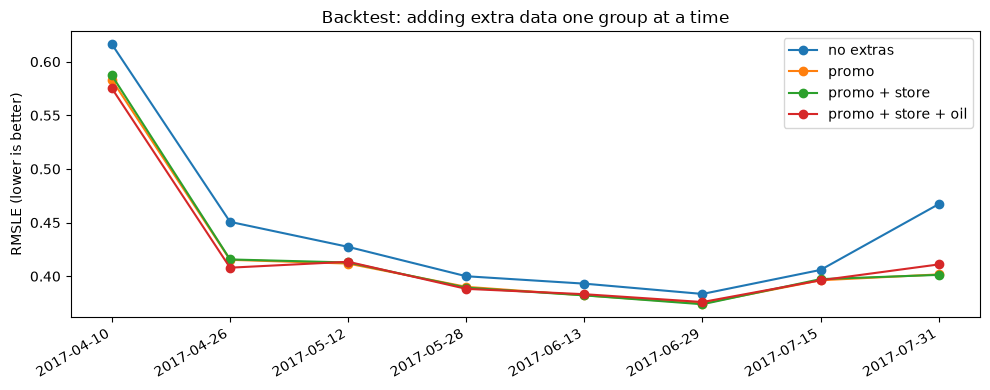

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in scores.columns:
    ax.plot(scores.index, scores[name], marker="o", label=name)
ax.set_ylabel("RMSLE (lower is better)")
ax.set_title("Backtest: adding extra data one group at a time")
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(f"{IMAGES}/extra_data_backtest.png", dpi=120)
plt.show()

**What we found:**
- **Promotions: a clear win.** About −0.024 on average, and better in **all 8 windows**. The biggest gain is in the newest
  window (0.467 → 0.40), which falls in the back-to-school season with many promotions.
- **Store info: no effect.** The mean changes by less than 0.001 and it wins only about half the windows: what noise looks like.
  `store_nbr` already tells the model everything type and cluster do.
- **Oil: no consistent effect either.** The mean improves by about 0.001, but it wins only half the windows and makes the
  newest window clearly worse. That's what we expected from the flat price since 2015.

Note also how much the scores move from window to window compared with these tiny differences: a 0.001 change in the mean
is far inside that noise. Another source of noise: early stopping picks a different number of trees in each run.

## 5. Decision and submission v4

**Keep promotions; leave store info and oil out.** A feature that doesn't win consistently adds complexity (more code,
more data to prepare, more ways to break) without a gain we can measure. If we kept every column that improved the mean
by 0.001, we'd slowly be tuning the model to these 8 windows.

In [8]:
data = prepare(build_table(train, stores, holidays, end="2017-08-31", extras=("promo",), test=test))
final_model, final_trees = fit(data, "2017-08-15")
test_dates = pd.DatetimeIndex(sorted(test["date"].unique()), name="date")
predicted = forecast(final_model, data, test_dates)

long = predicted.unstack().rename("sales").reset_index()
v4 = test.merge(long, on=["store_nbr", "family", "date"], how="left")[["id", "sales"]]
assert len(v4) == len(test) and v4["sales"].notna().all() and (v4["sales"] >= 0).all()
v4.to_csv("../submissions/v4_lightgbm_promo.csv", index=False)
print(f"Trees: {final_trees}")
v4.head()

Trees: 1296


,id,sales
0,3000888,3.892411
1,3002670,3.801449
2,3004452,4.536572
3,3006234,4.695189
4,3008016,1.957048


Upload `submissions/v4_lightgbm_promo.csv` to Kaggle. The backtest expects an improvement of about 0.02 over v3 (0.40358).

## Summary

| Finding | Consequence |
|---|---|
| Promotions are known in advance; future oil prices are not, even though they're in the file | Use the forecast day's promotions; oil only 16+ days old |
| Promotion days sell about 19% more on open days (36% if closed days are wrongly included) | Good for prediction; not proof of cause |
| Promotions improve the backtest in all 8 windows, mean 0.443 → 0.419 | Kept |
| Store info and oil change the mean by ~0.001, half the windows better | Left out: no consistent gain |

**Next step (step 8b):** v4's Kaggle score, and why it disagrees with the backtest (notebook 09).